# **FV Solver for the coupled Richards' and heat transport equation**

Author: Anne Hermann   \
anne.hermann@uni-tuebingen.de

In [1]:
import sys
sys.path.append('../../../')
import jax.numpy as jnp
from utils.geometry import Geom
from utils.petrophysic import effsat, watercontent, relperm
from utils import plotting_utils
import pickle as pkl
import matplotlib.pyplot as plt

In [2]:
parametrization = "permaFoam"
input_folder = "../../../input/era5_land_data/Sweden/"
input_filename = "spinup_2308_2311.pkl"

### Mesh Generation

In [3]:
dz = 0.025       # grid spacing [m]
dx = 0.025    # grid spacing [m]
ztot = 1       # height of the cross-sction [m]
xtot = 10    # length of the domain [m]
slope = -0.1   # slope of the domain [-]

geom = Geom(dx, dz, 0, xtot, -ztot, 0, slope)  # geometry object
geom.create_grid()

===============   Creating grid   =============== 
DONE: created grid with  400 x 40 cells.


In [4]:
geom.set_sparsity_pattern_coupled()
# plotting_utils.plot_sparsity_pattern(geom)

===============   Calculating coupled sparsity pattern   =============== 
DONE: calculated coupled sparsity pattern with 316480 nonzero entries.


### Time Discretisation

In [5]:
dt = 60     # time step [s]
t_end = 120*24*60*60 # end time [s]
maxdt = 6*60*60       # maximum time step [s]
CN = 1          # Crank-Nicolson weighting parameter implicit/explicit
save_t =24*60*60     # save time [s]
geom.time_discretization(dt, t_end, maxdt, CN, save_t) # time discretization

===============   Creating time discretization   =============== 
DONE: created time discretization.


### Hydraulic Parameters

In [6]:
# Sandy soil parameters
alpha = 14.5*jnp.ones((geom.nz,geom.nx))   # van Genuchten alpha [1/m]
Ksat = 8.25e-5*jnp.ones((geom.nz,geom.nx)) # saturated hydraulic conductivity [m/s]
N = 2.68*jnp.ones((geom.nz,geom.nx))       # van Genuchten N [-]
Theta_r = 0.045*jnp.ones((geom.nz,geom.nx))# minimum volumetric water content [-]
Theta_s = 0.43*jnp.ones((geom.nz,geom.nx)) # maximum volumetric water content [-]

# Loamy soil parameters
indices = jnp.where((geom.Z<=-.25+slope*geom.X) & (geom.Z>=-.5+slope*geom.X))
alpha = alpha.at[indices].set(1.6)
Ksat = Ksat.at[indices].set(6.94e-7)
N = N.at[indices].set(1.37)
Theta_r = Theta_r.at[indices].set(0.034)
Theta_s = Theta_s.at[indices].set(0.46)

geom.set_vanGenuchten_params(Ksat, alpha, N, Theta_r, Theta_s)

### Thermal Parameters

In [7]:
rho_l = 1000
rho_i = 917
rho_s = 2650
rho_a = 1200

c_s = 800
c_l = 4180
c_i = 2100
c_a = 1000

H_f = 3.34e5

geom.set_thermal_params(rho_l, rho_i, rho_s, rho_a, c_l, c_i, c_s, c_a, H_f)

### Top Boundary Condition

Text(0.5, 0, '$t$ $[d]$')

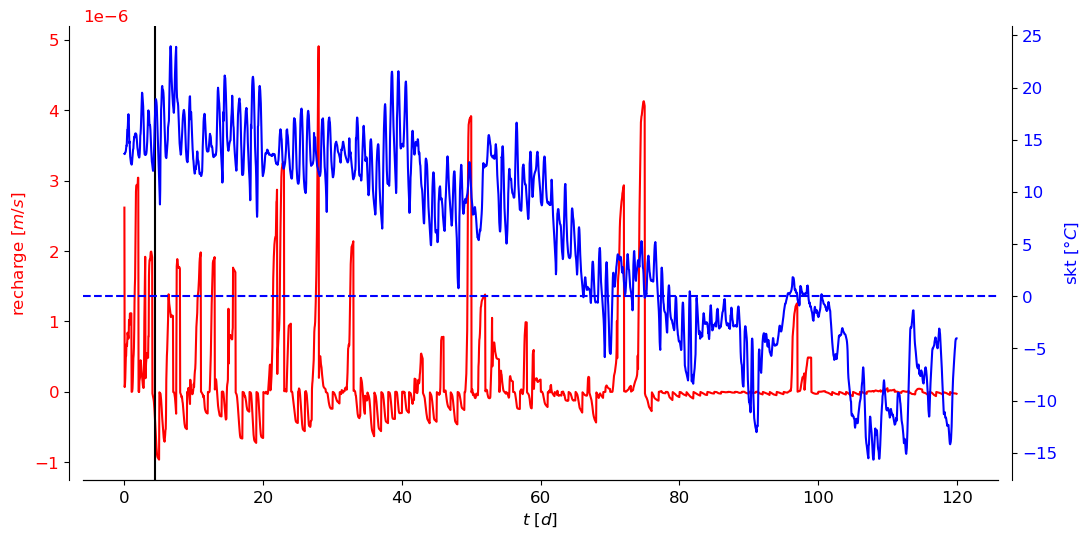

In [8]:
with open(input_folder + input_filename, "rb") as f:
    db = pkl.load(f)
    t_bc = jnp.array(db["time"])
    q_inf = jnp.array(db["recharge"])
    T_surface = jnp.array(db["skt"])

geom.set_surface_bc(t_bc, q_inf, T_surface)

t_plot = jnp.arange(0, t_end,3600)
cm = 1/2.54
fig, ax = plt.subplots(figsize=(30*cm, 15*cm))
ax.plot(t_plot/24/60/60, geom.q_inf_interp(t_plot), label="recharge", color="red")
ax.axvline(4.47, color="k", linestyle="-")
ax.set_ylabel("recharge $[m/s]$", color="red")
ax.tick_params(axis="y", labelcolor="red")

ax_cp = ax.twinx()
ax_cp.set_ylabel("skt $[°C]$", color="blue")
ax_cp.plot(t_plot/24/60/60, geom.T_surface_interp(t_plot), label="skt", color="blue")
ax_cp.tick_params(axis="y", labelcolor="blue")
ax_cp.axhline(0, color="blue", linestyle="--")

ax.spines["top"].set_visible(False)
ax_cp.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax_cp.spines["left"].set_visible(False)
ax.spines['left'].set_position(('outward', 10))
ax_cp.spines['right'].set_position(('outward', 10))

ax.set_xlabel("$t$ $[d]$")



### Initial Condition

In [9]:
h_gw  = jnp.min(geom.Z)+.25; # Grou jnp.linspace(1e-6,1,10000)
htot= jnp.ones((geom.nz,geom.nx))*h_gw
h_c = jnp.ones((geom.nz,geom.nx))*geom.Z-htot
h_c = h_c.at[jnp.where(h_c<0)].set(0)
Theta = watercontent(h_c,geom.alpha,geom.N,geom.Theta_s,geom.Theta_r)
T_init = (5*jnp.ones((geom.nz,geom.nx)))  # initial temperature 0 °C
t = 0
geom.set_initial_conditions(htot, h_c, Theta, 0*Theta, T_init)


===============   Setting initial conditions   =============== 
DONE: set initial conditions.


# Plotting initial condition

(<Figure size 1181.1x787.402 with 2 Axes>,
 <Axes: title={'center': 'Initial $T$'}, xlabel='x [m]', ylabel='z [m]'>)

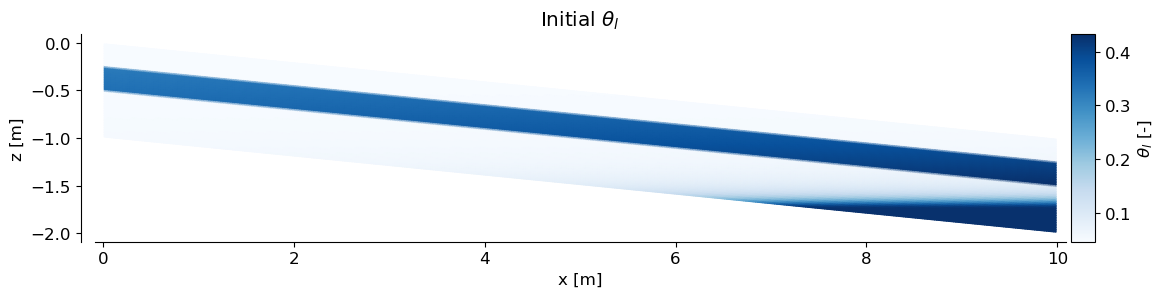

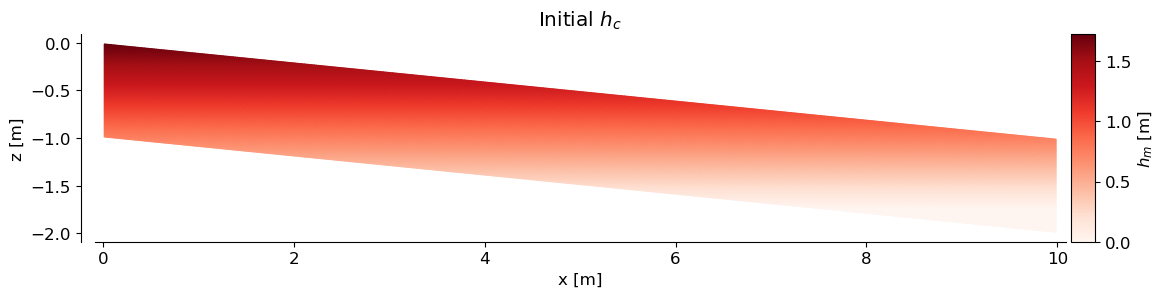

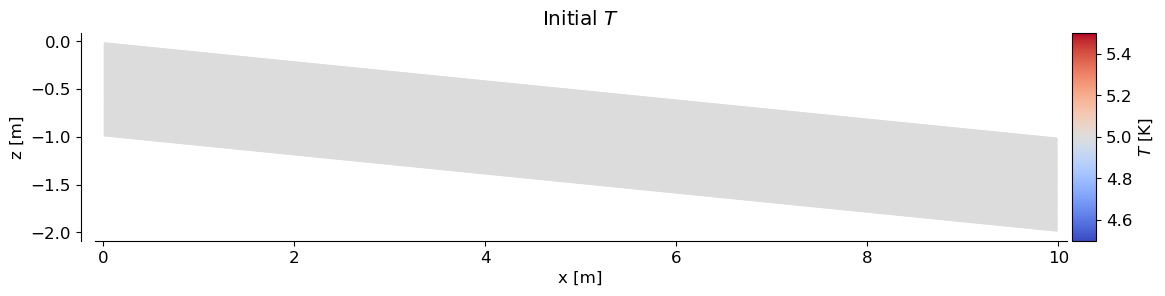

In [10]:
plotting_utils.plot_cellValues(geom.X,geom.Z, Theta, colormap="Blues", title=r"Initial $\theta_l$", colorbar_label=r'$\theta_l$ [-]')
plotting_utils.plot_cellValues(geom.X,geom.Z, h_c, colormap="Reds", title=r"Initial $h_c$", colorbar_label=r'$h_m$ [m]')
plotting_utils.plot_cellValues(geom.X,geom.Z, T_init, colormap="coolwarm", title=r"Initial $T$", colorbar_label=r'$T$ [K]')


# Numerical Parameters

In [11]:
restol=1e-4;      # accepted residual in Newton step
maxiter=20;      # maxmum number of iterations in Newton step
miniter=5;        # minimum number of iterations in Newton step

geom.set_solver_params(restol, maxiter, miniter,solver='newton')

===============   Setting Newton-Raphson parameters   =============== 
Restol: 0.0001
Max Iterations: 20
Min Iterations: 5
DONE: set Newton-Raphson parameters.


# Simulation 

In [12]:
[h_total, h_c_total, theta_l_total,theta_i_total, T_total, q_runoff_array, qx_array,qz_array,qx_centered_array,qz_centered_array, time_array, iter_total, normres_total] = geom.simulate_coupled(parametrization=parametrization)

TypeError: vertical_flux_update() takes 10 positional arguments but 11 were given

# Save simulation output in pickle file

In [ ]:
db = {"X": geom.X, "Z":geom.Z,"X_plot":geom.X_plot, "Z_plot":geom.Z_plot, "h_total": h_total, "h_c_total": h_c_total,"theta_l_total":theta_l_total, "theta_i_total":theta_i_total,"T_total": T_total,"q_runoff":q_runoff_array, "qx_array":qx_array,"qz_array":qz_array,"qx_centered_array":qx_centered_array,"qz_centered_array":qz_centered_array,"time_array": time_array, "iter_total": iter_total, "normres_total": normres_total}
with open(f"../../../output/Simulations_Paper/ERA5_Sweden/spinup/spinup_{parametrization}_omega50.pkl", 'wb') as pickle_file:
    pkl.dump(db, pickle_file)

(<Figure size 1181.1x787.402 with 2 Axes>,
 <Axes: title={'center': 't=10374979.6875'}, xlabel='x [m]', ylabel='z [m]'>)

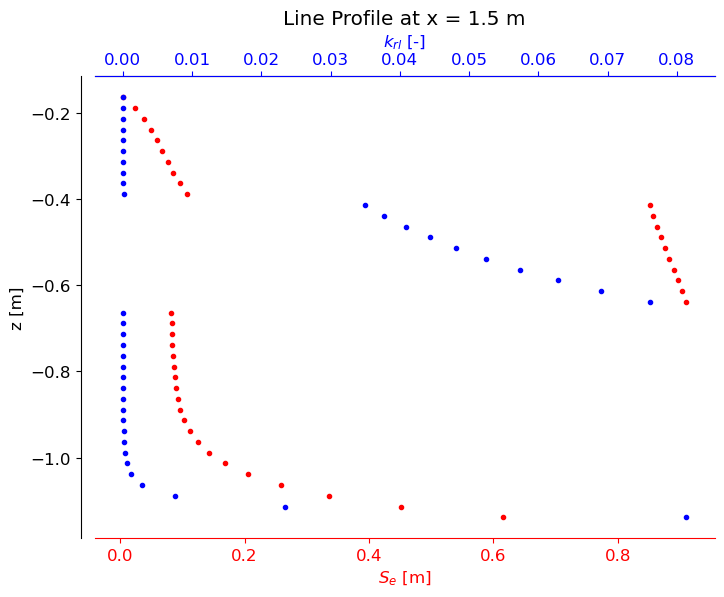

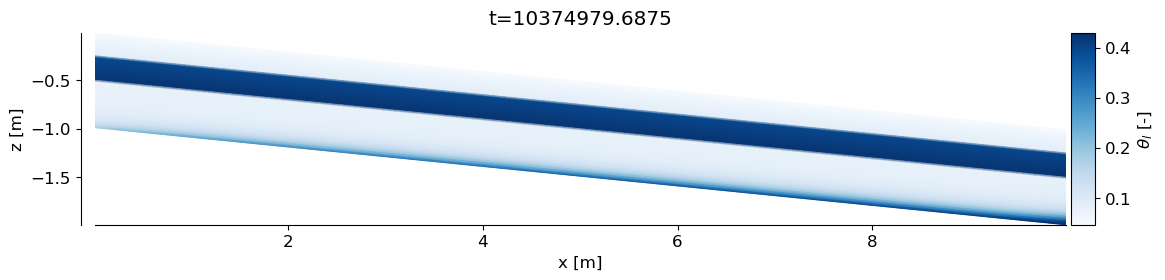

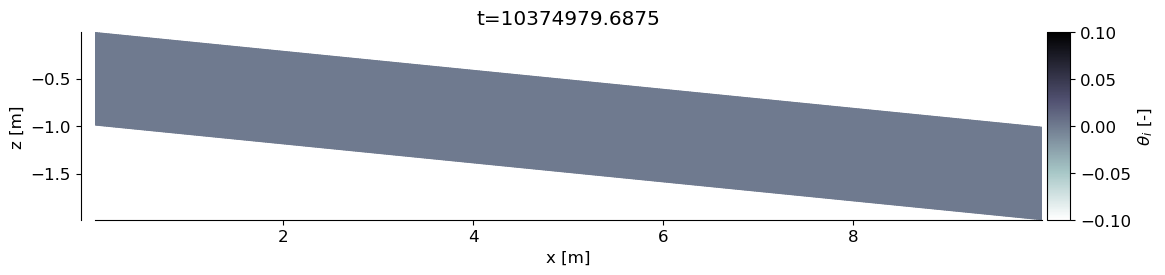

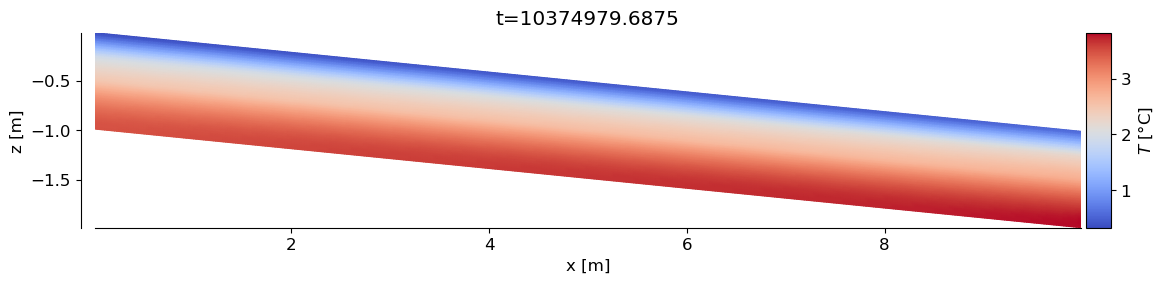

In [ ]:
index = -1  # final time step
Se = effsat(h_c_total[index],geom.alpha,geom.N)
kr = relperm(Se,geom.N)
plotting_utils.plot_lineProfile(geom, Se, kr, x_position=60, xlabel1=r"$S_e$ [m]", xlabel2=r"$k_{rl}$ [-]")

plotting_utils.plot_cellValues(geom.X,geom.Z, theta_l_total[index], colormap="Blues", title=f"t={time_array[index]}", colorbar_label=r'$\theta_l$ [-]')
plotting_utils.plot_cellValues(geom.X,geom.Z, theta_i_total[index], colormap="bone_r", title=f"t={time_array[index]}", colorbar_label=r'$\theta_i$ [-]')
plotting_utils.plot_cellValues(geom.X,geom.Z, T_total[index], colormap="coolwarm", title=f"t={time_array[index]}", colorbar_label=r'$T$ [°C]')